Autor:  
Manuel Eugenio Morocho Cayamcela, PhD

Enviado por: 
Darío Julián Echeverría Castro

## Procesamiento y Transformación de Datos para Análisis de Crédito
## **Kaggle Competition**

### **1. Introducción:**

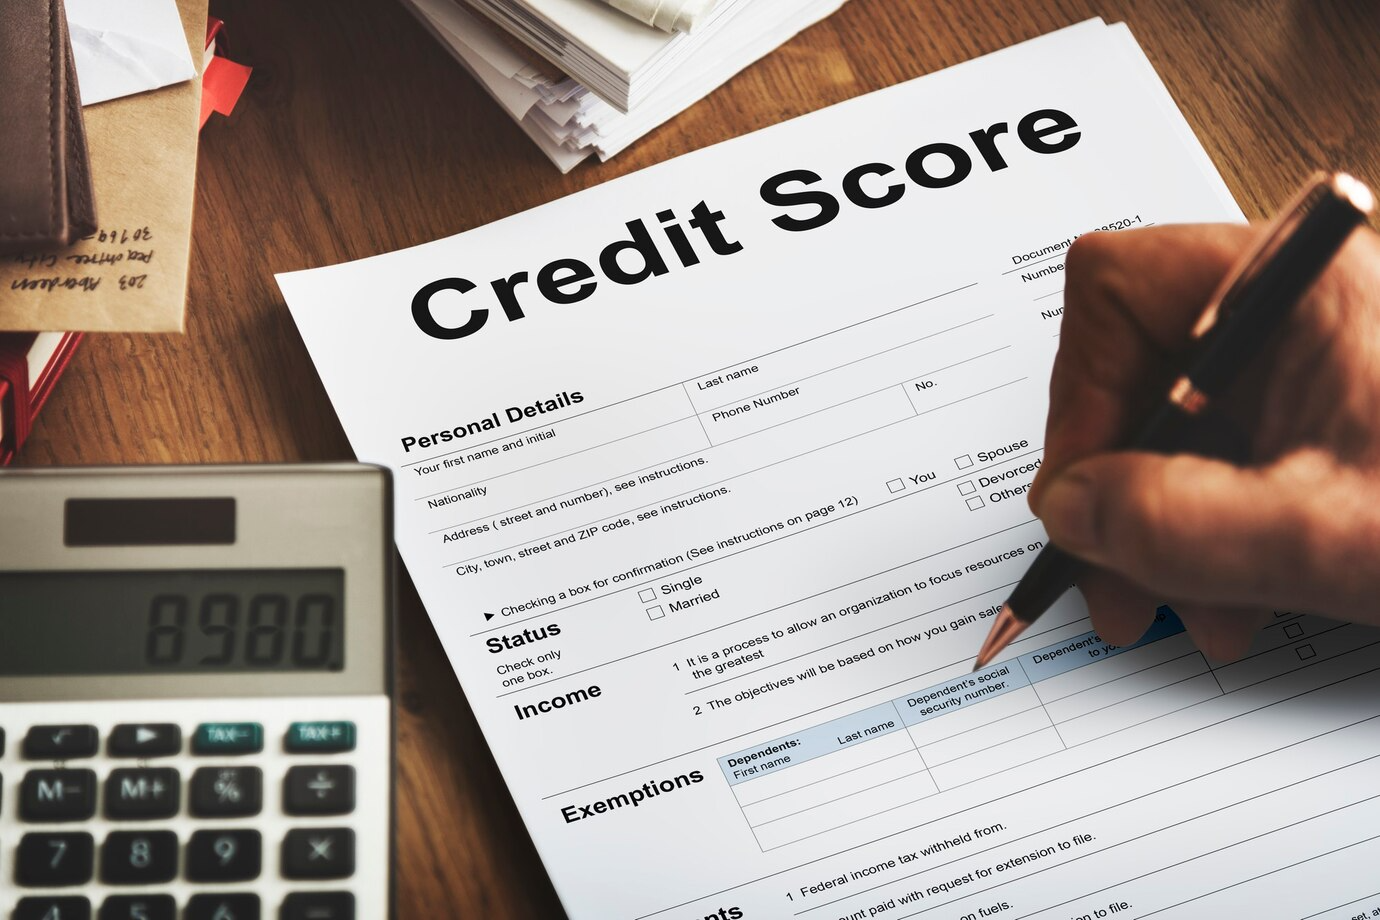

¡Bienvenidos a su primer desafío práctico en el módulo de Fundamentos de Inteligencia Artificial!

Hoy trabajarán en grupos para limpiar un dataset con errores, inconsistencias y valores faltantes. 
El objetivo es aplicar lo aprendido sobre preprocesamiento y limpieza de datos.

El modelo de clasificación ya está definido y no podrá ser modificado. La calidad de sus resultados dependerá exclusivamente de qué tan bien limpien y preparen los datos para el modelo.

Al final del día, cada grupo subirá sus predicciones a Kaggle, y la puntuación del leaderboard será parte de la calificación, junto con una rúbrica cualitativa.

Utilizaremos un conjunto de datos de solicitudes de crédito con las siguientes columnas:

1. ID: Identificador único para cada registro.
2. Customer_ID: Identificador único para cada cliente.
3. Month: Mes en el que se registró la información.
4. Name: Nombre del cliente.
5. Age: Edad del cliente.
6. SSN: Número de Seguro Social del cliente.
7. Occupation: Ocupación del cliente.
8. Annual_Income: Ingreso anual del cliente.
9. Monthly_Inhand_Salary: Salario mensual disponible del cliente.
10. Num_Bank_Accounts: Número de cuentas bancarias del cliente.
11. Num_Credit_Card: Número de tarjetas de crédito del cliente.
12. Interest_Rate: Tasa de interés aplicada al cliente.
13. Num_of_Loan: Número de préstamos del cliente.
14. Type_of_Loan: Tipo de préstamo(s) del cliente.
15. Delay_from_due_date: Retraso desde la fecha de vencimiento del pago.
16. Num_of_Delayed_Payment: Número de pagos retrasados del cliente.
17. Changed_Credit_Limit: Límite de crédito modificado del cliente.
18. Num_Credit_Inquiries: Número de consultas de crédito realizadas por el cliente.
19. Credit_Mix: Mezcla de crédito del cliente.
20. Outstanding_Debt: Deuda pendiente del cliente.
21. Credit_Utilization_Ratio: Relación de utilización de crédito del cliente.
22. Credit_History_Age: Antigüedad del historial de crédito del cliente.
23. Payment_of_Min_Amount: Pago del monto mínimo realizado por el cliente.
24. Total_EMI_per_month: Total de cuotas mensuales del cliente.
25. Amount_invested_monthly: Cantidad invertida mensualmente por el cliente.
26. Payment_Behaviour: Comportamiento de pago del cliente.
27. Monthly_Balance: Saldo mensual del cliente.
28. Credit_Score: Puntuación de crédito del cliente.

### **2. Kaggle instructions**

1. Unirse a la competencia en Kaggle.
2. Una vez dentro de la competencia, descarguen los archivos: `train.csv`, `test.csv`, y `sample_submission.csv`.
3. Realicen la limpieza del archivo `train.csv` según los pasos que consideren adecuados.
4. Entrenen el modelo provisto en este notebook (NO modificar los parámetros ni reemplazar el modelo).
5. Apliquen la limpieza equivalente al `test.csv`, generen las predicciones y súbanlas a Kaggle en formato del `sample_submission.csv`.
6. El estudiante debe documentar los pasos de limpieza aplicados en su notebook Kaggle (comentarios y celdas Markdown).

### **3. Data Cleaning**

En esta sección deben realizar las tareas de limpieza de datos necesarias:

- Imputación de valores nulos
- Eliminación o codificación de outliers
- Conversión de variables categóricas
- Escalado si es necesario
- Otras transformaciones relevantes

**IMPORTANTE:** todos estos pasos deben replicarse también en el test.csv antes de predecir.

### 4. Código

**Resumen de lo ejecutado:**
- Caracterización inicial y porcentaje de valores nulos.
- Limpieza preliminar: conversión a numérico de variables almacenadas como texto y de `Credit_History_Age` a meses.
- Marcadores basura (`_______`, `_`, `!@9#%8`, `10000`, `-333…`) transformados a NaN.
- Tratamiento de valores atípicos:
    - Boxplots previos y cálculo del rango intercuartílico (IQR).
    - Valores fuera de límites reemplazados por NaN (IQR ajustado por variable; `Annual_Income` se trata aparte).
    - Boxplots posteriores al tratamiento.
- `Type_of_Loan` NaN → categoría `No Loan` y `Num_of_Loan = 0`.
- Imputación por cliente (`Customer_ID`): mes previo/siguiente con dato; `Annual_Income` con la moda del cliente; respaldo con `Annual_Income / 12`, mediana o moda global.
- Análisis exploratorio post-imputación: distribuciones y relevancia frente a `Credit_Score` (eta² e información mutua).
- Codificación de variables categóricas: multi-hot (`Type_of_Loan`), ordinal (`Credit_Mix`) y one-hot (resto).
- Limpieza equivalente de `X_test`, imputando junto con el train porque comparten clientes.
- Eliminación de variables sin aporte (`Occupation`, `Payment_Behaviour`, `Type_of_Loan`, `Credit_Utilization_Ratio`, `Total_EMI_per_month`).
- Escalado: no aplicado, porque el modelo predefinido es Random Forest.

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.preprocessing import StandardScaler

In [10]:
# Carga de archivos
df_x_train = pd.read_csv('iisem-2026-mcd-credit-score/X_train_Kaggle.csv')
df_x_test = pd.read_csv('iisem-2026-mcd-credit-score/X_test_Kaggle.csv')
df_y_train = pd.read_csv('iisem-2026-mcd-credit-score/y_train_Kaggle.csv')

df_x_train.head()

C:\Users\darth\AppData\Local\Temp\ipykernel_8568\2655721739.py:2: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  df_x_train = pd.read_csv('iisem-2026-mcd-credit-score/X_train_Kaggle.csv')


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x1d653,CUS_0xa037,February,Aruna Viswanathap,21,318-64-2372,Manager,151649.36,12823.446667,3,...,3.0,Good,358.17,38.252928,29 Years and 11 Months,No,224.703133,763.4809808066542,Low_spent_Large_value_payments,564.1605530687996
1,0x177f0,CUS_0x1aee,July,Klaymanp,26,065-68-6043,Accountant,100465.13999999998,8279.095000,4,...,2.0,Good,990.2,40.708250,32 Years and 9 Months,No,0.000000,155.12209196021695,High_spent_Large_value_payments,912.787408039783
2,0xb618,CUS_0x8d56,March,George Georgiopoulosv,37,063-47-6931,Engineer,43395.09,3562.257500,1,...,4.0,_,1103.7,35.041464,32 Years and 7 Months,NM,74.869250,178.811691303449,High_spent_Small_value_payments,362.5448082410094
3,0x150a5,CUS_0x8a8e,April,Yereth Rosend,34,#F%$D@*&8,Lawyer,80661.32,NaN,5,...,5.0,Standard,1482.15,33.109288,7 Years and 6 Months,Yes,135.562474,232.1346014840457,High_spent_Small_value_payments,547.4805911079858
4,0x19546,CUS_0x43d0,May,Camposb,3194,309-30-6070,Scientist,81506.32,7012.193333,7,...,5.0,Standard,933.67,27.513472,9 Years and 8 Months,NM,92.506250,318.73385010196097,High_spent_Small_value_payments,549.9792335289444


In [3]:
df_x_train.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,70000,70000,0x1d653,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,70000,12498,CUS_0x59a5,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,70000,8,May,8814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,63016,10132,Stevex,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,70000,1302,28,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SSN,70000,12499,#F%$D@*&8,3909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,70000,16,_______,4951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,70000,17274,20867.67,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Inhand_Salary,59510.0,NaN,NaN,NaN,4201.948265,3175.780459,303.645417,1633.646667,3107.431667,5971.186667,15204.633333
Num_Bank_Accounts,70000.0,NaN,NaN,NaN,17.419629,118.820416,-1.0,3.0,6.0,7.0,1798.0


In [11]:
# Porcentaje de NA iniciales
list_columns = df_x_train.columns.tolist()

print("Porcentaje de valores nulos por columna:")
for col in list_columns:
    na_count = df_x_train[col].isna().sum()
    percentage = na_count/len(df_x_train)
    if percentage > 0:
        print(f"{col}: {na_count} {percentage:.2%}")
        if pd.api.types.is_numeric_dtype(df_x_train[col]):
            print(f"    Min: {df_x_train[col].min()}")
            print(f"    Max: {df_x_train[col].max()}")
            print(f"    Mean: {df_x_train[col].mean()}")
            print(f"    Std: {df_x_train[col].std()}")
print("\n")

# Filas con NA
filas_con_na = df_x_train.isna().any(axis=1).mean() * 100
print(f"% filas con al menos un NA: {filas_con_na:.2f}%")

# Cantidad de filas según cuántos NA tienen
df_x_train.isna().sum(axis=1).value_counts().sort_index()

Porcentaje de valores nulos por columna:
Name: 6984 9.98%
Monthly_Inhand_Salary: 10490 14.99%
    Min: 303.6454166666666
    Max: 15204.633333333331
    Mean: 4201.948264773173
    Std: 3175.7804593611218
Type_of_Loan: 8027 11.47%
Num_of_Delayed_Payment: 4927 7.04%
Num_Credit_Inquiries: 1403 2.00%
    Min: 0.0
    Max: 2597.0
    Mean: 27.870052626208142
    Std: 193.1742405518869
Credit_History_Age: 6321 9.03%
Amount_invested_monthly: 3135 4.48%
Monthly_Balance: 833 1.19%


% filas con al menos un NA: 46.98%


0    37116
1    24802
2     7012
3      991
4       74
5        5
Name: count, dtype: int64

De manera preliminar, **no es factible eliminar los registros con NA** pues son casi la mitad del conjunto de datos de entrenamiento.

Se dio inicio a la impieza preliminar:

In [17]:
# Conversión a numérico de las columnas que deberían ser numéricas pero están como object
# - Limpieza de caracter "_" y conversión a número
df_x_train_cl = df_x_train.copy()

cols_guion = ['Num_of_Loan', 'Age', 'Annual_Income', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']

for col in cols_guion:
    df_x_train_cl[col] = pd.to_numeric(
        df_x_train_cl[col].astype(str).str.replace('_', '', regex=False),
        errors='coerce'
    )

# Transformación a dato utulizable de la columna "Credit_History_Age" (que está en formato "X Years Y Months")
anios_meses = df_x_train_cl['Credit_History_Age'].str.extract(r'(\d+)\s*Years?\D*(\d+)\s*Months?')
df_x_train_cl['Credit_History_Age'] = anios_meses[0].astype(float) * 12 + anios_meses[1].astype(float)

df_x_train_cl[cols_guion + ['Credit_History_Age']].dtypes

Num_of_Loan                  int64
Age                          int64
Annual_Income              float64
Num_of_Delayed_Payment     float64
Changed_Credit_Limit       float64
Outstanding_Debt           float64
Amount_invested_monthly    float64
Monthly_Balance            float64
Credit_History_Age         float64
dtype: object

In [18]:
# Porcentaje de NA posterior a limpieza y conversión a numérico
list_columns = df_x_train_cl.columns.tolist()

print("Porcentaje de valores nulos por columna:")
for col in list_columns:
    na_count = df_x_train_cl[col].isna().sum()
    percentage = na_count/len(df_x_train_cl)
    if percentage > 0:
        print(f"{col}: {na_count} {percentage:.2%}")
        if pd.api.types.is_numeric_dtype(df_x_train_cl[col]):
            print(f"    Min: {df_x_train_cl[col].min()}")
            print(f"    Max: {df_x_train_cl[col].max()}")
            print(f"    Mean: {df_x_train_cl[col].mean()}")
            print(f"    Std: {df_x_train_cl[col].std()}")
print("\n")

# Filas con NA
filas_con_na = df_x_train_cl.isna().any(axis=1).mean() * 100
print(f"% filas con al menos un NA: {filas_con_na:.2f}%")

# Cantidad de filas según cuántos NA tienen
df_x_train_cl.isna().sum(axis=1).value_counts().sort_index()

Porcentaje de valores nulos por columna:
Name: 6984 9.98%
Monthly_Inhand_Salary: 10490 14.99%
    Min: 303.6454166666666
    Max: 15204.633333333331
    Mean: 4201.948264773173
    Std: 3175.7804593611218
Type_of_Loan: 8027 11.47%
Num_of_Delayed_Payment: 4927 7.04%
    Min: -3.0
    Max: 4388.0
    Mean: 31.179506093156917
    Std: 228.23382326591098
Changed_Credit_Limit: 1490 2.13%
    Min: -6.49
    Max: 36.97
    Mean: 10.384918989928478
    Std: 6.776967275701666
Num_Credit_Inquiries: 1403 2.00%
    Min: 0.0
    Max: 2597.0
    Mean: 27.870052626208142
    Std: 193.1742405518869
Credit_History_Age: 6321 9.03%
    Min: 1.0
    Max: 404.0
    Mean: 221.4441024513576
    Std: 99.62965821410043
Amount_invested_monthly: 3135 4.48%
    Min: 0.0
    Max: 10000.0
    Mean: 632.9393496690117
    Std: 2033.2187444147532
Monthly_Balance: 833 1.19%
    Min: -3.333333333333333e+26
    Max: 1602.0405189622518
    Mean: -3.373477718179671e+22
    Std: 3.3532000021512057e+24


% filas con al menos

0    36345
1    25021
2     7424
3     1105
4       99
5        6
Name: count, dtype: int64

Es necesaria la limpieza adicional para valores completamente atípicos y que no guardan relación con los datos.

In [20]:
# Marcadores basura transformados a NA
df_x_train_cl['Occupation'] = df_x_train_cl['Occupation'].replace('_______', np.nan)
df_x_train_cl['Credit_Mix'] = df_x_train_cl['Credit_Mix'].replace('_', np.nan)
df_x_train_cl['Payment_Behaviour'] = df_x_train_cl['Payment_Behaviour'].replace('!@9#%8', np.nan)
df_x_train_cl['Amount_invested_monthly'] = df_x_train_cl['Amount_invested_monthly'].replace(10000, np.nan)
df_x_train_cl['Monthly_Balance'] = df_x_train_cl['Monthly_Balance'].replace(-333333333333333333333333333, np.nan)

In [21]:
# Porcentaje de NA posterior a limpieza de valores y transformación a valores numéricos
list_columns = df_x_train_cl.columns.tolist()

print("Porcentaje de valores nulos por columna:")
for col in list_columns:
    na_count = df_x_train_cl[col].isna().sum()
    percentage = na_count/len(df_x_train_cl)
    if percentage > 0:
        print(f"{col}: {na_count} {percentage:.2%}")
        if pd.api.types.is_numeric_dtype(df_x_train_cl[col]):
            print(f"    Min: {df_x_train_cl[col].min()}")
            print(f"    Max: {df_x_train_cl[col].max()}")
            print(f"    Mean: {df_x_train_cl[col].mean()}")
            print(f"    Std: {df_x_train_cl[col].std()}")
print("\n")

# Filas con NA
filas_con_na = df_x_train_cl.isna().any(axis=1).mean() * 100
print(f"% filas con al menos un NA: {filas_con_na:.2f}%")

# Cantidad de filas según cuántos NA tienen
df_x_train_cl.isna().sum(axis=1).value_counts().sort_index()

Porcentaje de valores nulos por columna:
Name: 6984 9.98%
Occupation: 4951 7.07%
Monthly_Inhand_Salary: 10490 14.99%
    Min: 303.6454166666666
    Max: 15204.633333333331
    Mean: 4201.948264773173
    Std: 3175.7804593611218
Type_of_Loan: 8027 11.47%
Num_of_Delayed_Payment: 4927 7.04%
    Min: -3.0
    Max: 4388.0
    Mean: 31.179506093156917
    Std: 228.23382326591098
Changed_Credit_Limit: 1490 2.13%
    Min: -6.49
    Max: 36.97
    Mean: 10.384918989928478
    Std: 6.776967275701666
Num_Credit_Inquiries: 1403 2.00%
    Min: 0.0
    Max: 2597.0
    Mean: 27.870052626208142
    Std: 193.1742405518869
Credit_Mix: 14143 20.20%
Credit_History_Age: 6321 9.03%
    Min: 1.0
    Max: 404.0
    Mean: 221.4441024513576
    Std: 99.62965821410043
Amount_invested_monthly: 6117 8.74%
    Min: 0.0
    Max: 1977.326102249349
    Mean: 195.6935274739518
    Std: 199.98166217479002
Payment_Behaviour: 5358 7.65%
Monthly_Balance: 840 1.20%
    Min: 0.0077596647753352
    Max: 1602.0405189622518
   

0    23859
1    27178
2    13971
3     4149
4      742
5       90
6       11
Name: count, dtype: int64

In [25]:
df_x_train_cl.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,70000,70000,0x1d653,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,70000,12498,CUS_0x59a5,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,70000,8,May,8814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,63016,10132,Stevex,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,70000.0,NaN,NaN,NaN,110.054514,684.858905,-500.0,24.0,33.0,42.0,8698.0
SSN,70000,12499,#F%$D@*&8,3909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,65049,15,Lawyer,4620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,70000.0,NaN,NaN,NaN,178001.556026,1445765.292513,7005.93,19531.84,37755.92,72817.02,24198062.0
Monthly_Inhand_Salary,59510.0,NaN,NaN,NaN,4201.948265,3175.780459,303.645417,1633.646667,3107.431667,5971.186667,15204.633333
Num_Bank_Accounts,70000.0,NaN,NaN,NaN,17.419629,118.820416,-1.0,3.0,6.0,7.0,1798.0


In [42]:
df_x_train_cl[df_x_train_cl['Num_Bank_Accounts'] > 1000]

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
24,0x18d4b,CUS_0x7960,February,Silke Koltrowitzp,36,#F%$D@*&8,Lawyer,125179.95,10173.662500,1285,...,2.0,NaN,1344.09,36.506156,190.0,No,0.000000,714.712503,Low_spent_Small_value_payments,592.653747
115,0x1dc6f,CUS_0x4505,June,Ross Kerberb,55,814-20-6857,Developer,20257.28,1916.106667,1306,...,2.0,Standard,966.07,32.256958,320.0,Yes,10.776501,123.186722,NaN,327.647443
144,0x10569,CUS_0x849d,April,Baynesa,35,730-96-4622,Media_Manager,174826.76,14584.896667,1766,...,514.0,Good,819.92,35.497525,344.0,NM,279.604894,575.823289,NaN,883.061484
149,0x3cc7,CUS_0xae8,February,Milesk,40,433-92-1005,Teacher,16716.53,1519.044167,1769,...,6.0,Bad,4116.03,25.988806,78.0,Yes,79.662374,101.314688,Low_spent_Large_value_payments,240.927355
255,0x13585,CUS_0x98c2,August,Stampp,37,457-88-9588,Developer,48646.50,4230.875000,1558,...,3.0,Standard,723.55,37.268936,246.0,Yes,0.000000,262.959353,NaN,420.128147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69713,0x1120e,CUS_0xaf18,January,Scottq,21,627-46-2774,NaN,28174.70,2259.891667,1733,...,7.0,Bad,2053.10,37.563917,119.0,Yes,42.211477,NaN,High_spent_Medium_value_payments,367.098381
69734,0x2090,CUS_0xacbe,March,Henryg,38,406-29-0152,Media_Manager,10034.55,719.212500,1388,...,5.0,Standard,1669.84,33.921760,113.0,Yes,41.082547,33.244122,Low_spent_Medium_value_payments,277.594581
69792,0x1fd91,CUS_0x3811,April,Regann,44,305-88-2648,Lawyer,82668.78,6930.065000,1444,...,0.0,Standard,540.04,31.672835,292.0,Yes,55.699665,154.294587,High_spent_Large_value_payments,723.012248
69874,0x1e841,CUS_0x4f32,August,Andjarsario,51,916-10-7140,Musician,32469.29,2738.774167,1102,...,6.0,Good,129.41,38.840823,227.0,NM,0.000000,49.943375,High_spent_Medium_value_payments,473.934041


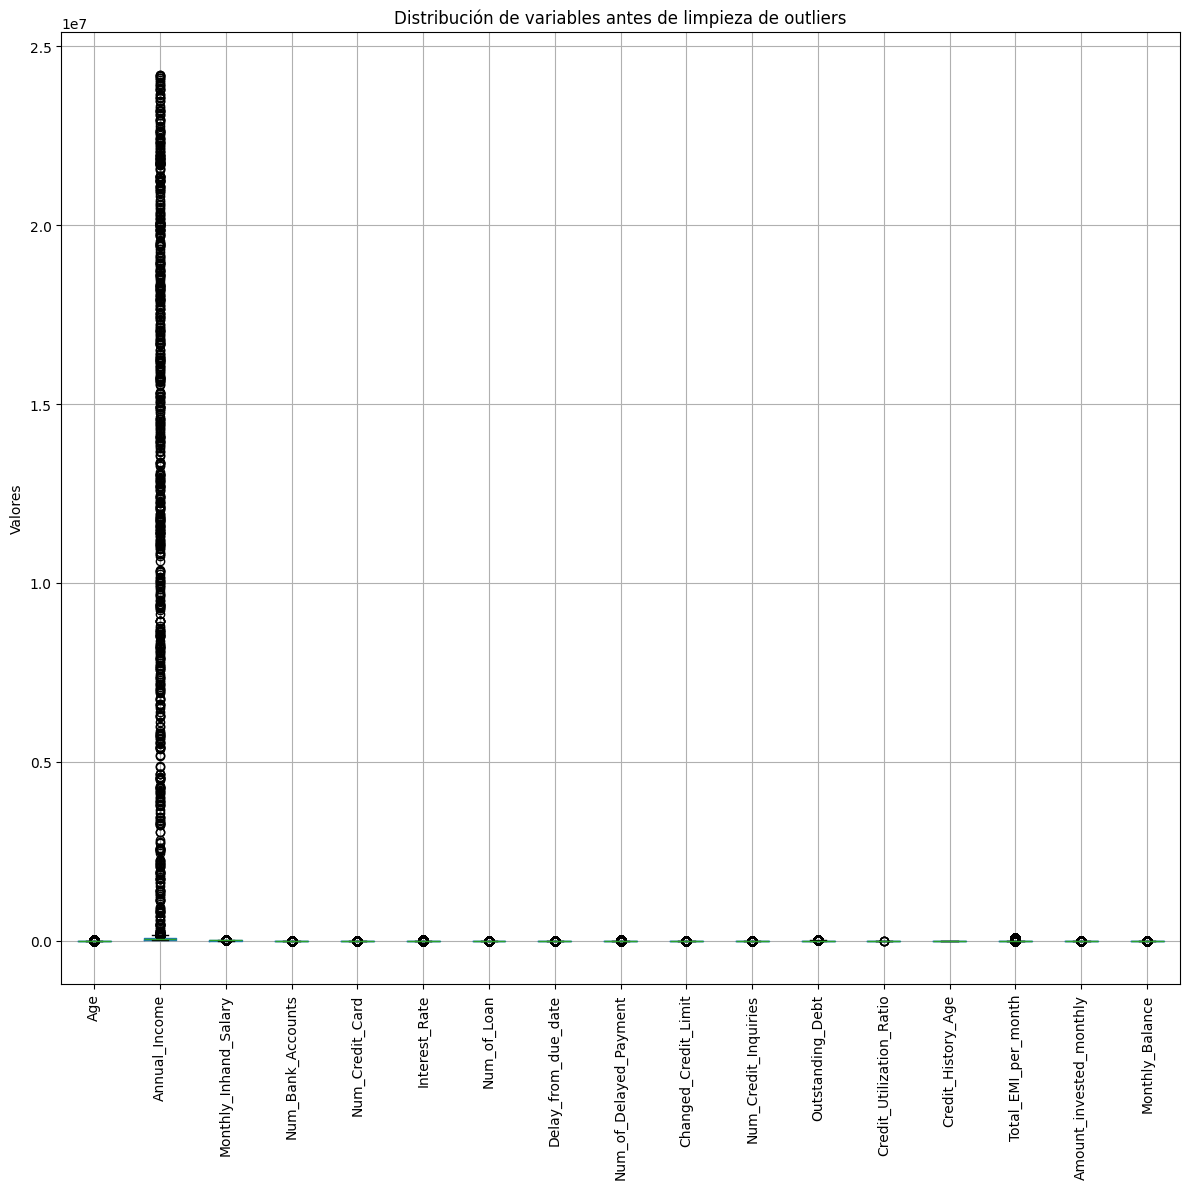

In [22]:
# Boxplots previo a limpieza de valores atípicos
plt.figure(figsize=(12, 12))
df_x_train_cl.boxplot(rot=90)
plt.title('Distribución de variables antes de limpieza de outliers')
plt.ylabel('Valores')
plt.tight_layout()
plt.show()

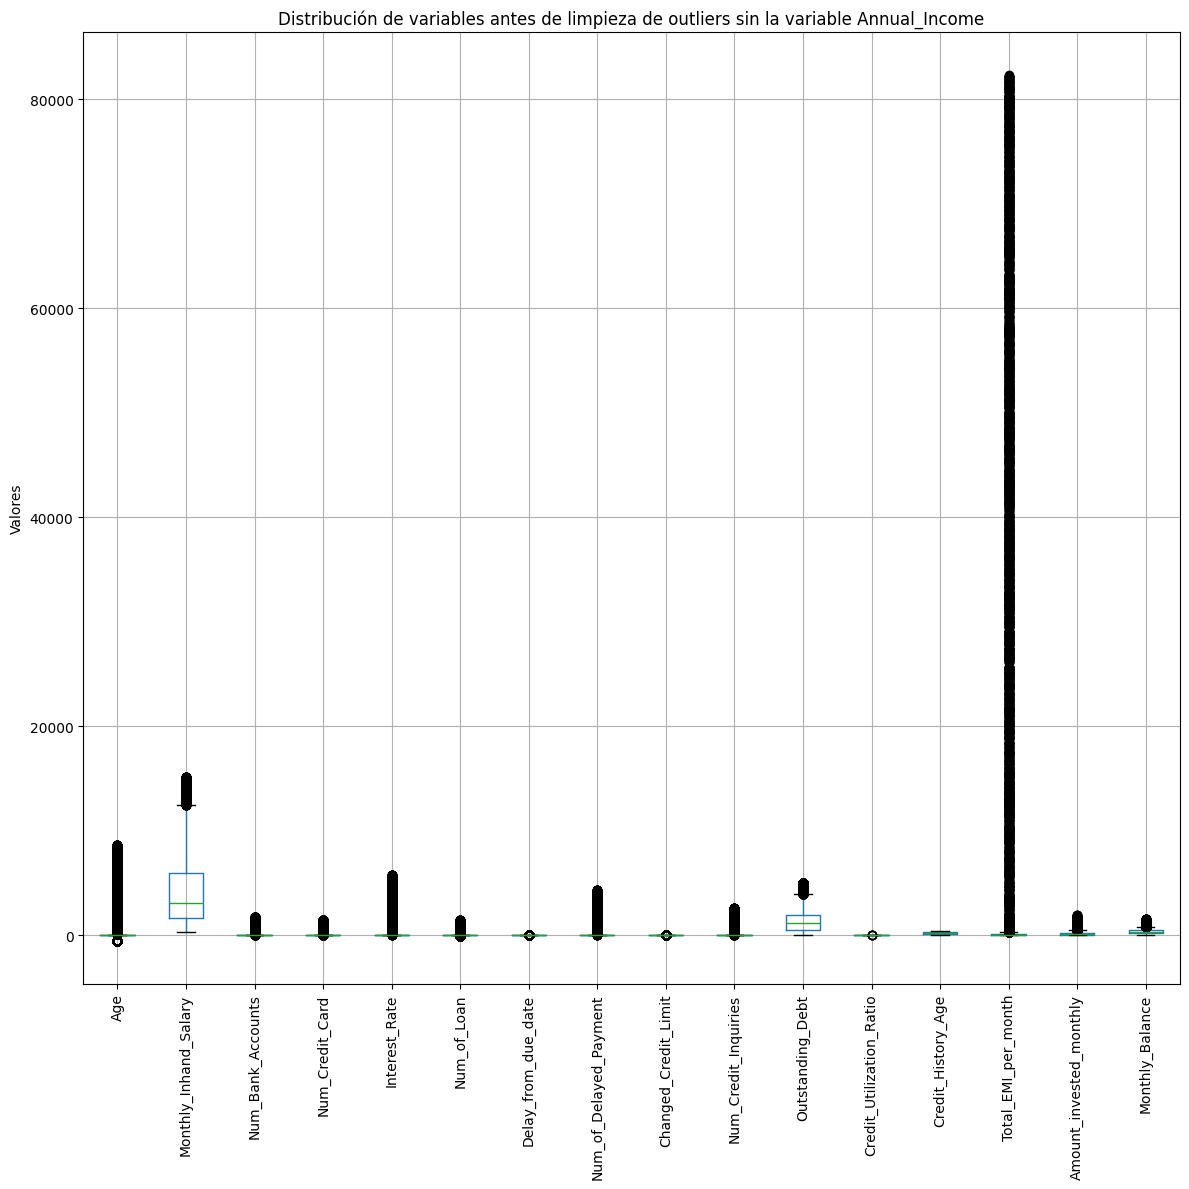

In [39]:
# Boxplots previo a limpieza de valores atípicos sin Annual Income
plt.figure(figsize=(12, 12))
df_x_train_cl.drop(columns=['Annual_Income']).boxplot(rot=90)
plt.title('Distribución de variables antes de limpieza de outliers sin la variable Annual_Income')
plt.ylabel('Valores')
plt.tight_layout()
plt.show()

In [23]:
# Cálculo de rangos intercuartílicos (IQR) y límites para detección de outliers
iqr_limits = {}

for col in df_x_train_cl.columns:
    if pd.api.types.is_numeric_dtype(df_x_train_cl[col]):
        q1 = df_x_train_cl[col].quantile(0.25)
        q3 = df_x_train_cl[col].quantile(0.75)
        iqr = q3 - q1
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        print(f"{col}: Lower Limit = {lower_limit}, Upper Limit = {upper_limit}")
        iqr_limits[col] = {'lower': lower_limit, 'upper': upper_limit}

Age: Lower Limit = -3.0, Upper Limit = 69.0
Annual_Income: Lower Limit = -60395.93000000002, Upper Limit = 152744.79000000004
Monthly_Inhand_Salary: Lower Limit = -4872.663333333335, Upper Limit = 12477.49666666667
Num_Bank_Accounts: Lower Limit = -3.0, Upper Limit = 13.0
Num_Credit_Card: Lower Limit = -0.5, Upper Limit = 11.5
Interest_Rate: Lower Limit = -10.0, Upper Limit = 38.0
Num_of_Loan: Lower Limit = -5.0, Upper Limit = 11.0
Delay_from_due_date: Lower Limit = -17.0, Upper Limit = 55.0
Num_of_Delayed_Payment: Lower Limit = -4.5, Upper Limit = 31.5
Changed_Credit_Limit: Lower Limit = -8.94, Upper Limit = 29.14
Num_Credit_Inquiries: Lower Limit = -6.0, Upper Limit = 18.0
Outstanding_Debt: Lower Limit = -1491.8925000000002, Upper Limit = 3989.4075000000003
Credit_Utilization_Ratio: Lower Limit = 15.354649295212457, Upper Limit = 49.19945581052059
Credit_History_Age: Lower Limit = -90.5, Upper Limit = 537.5
Total_EMI_per_month: Lower Limit = -167.78263063480225, Upper Limit = 360.418

Valores atípicos reemplazados por NaN:
Age [-3.0, 120]: 1922 (2.75%)
Monthly_Inhand_Salary [0, inf]: 0 (0.00%)
Num_Bank_Accounts [0, 13.0]: 956 (1.37%)
Num_Credit_Card [-0.5, 11.5]: 1598 (2.28%)
Interest_Rate [-10.0, 38.0]: 1447 (2.07%)
Num_of_Loan [0, 11.0]: 3057 (4.37%)
Num_of_Delayed_Payment [0, 31.5]: 974 (1.39%)
Num_Credit_Inquiries [0, 18.0]: 1181 (1.69%)
Outstanding_Debt [0, inf]: 0 (0.00%)
Credit_History_Age [0, inf]: 0 (0.00%)
Total_EMI_per_month [-167.78263063480225, 360.41873493198716]: 4746 (6.78%)
Amount_invested_monthly [0, inf]: 0 (0.00%)
Monthly_Balance [0, inf]: 0 (0.00%)


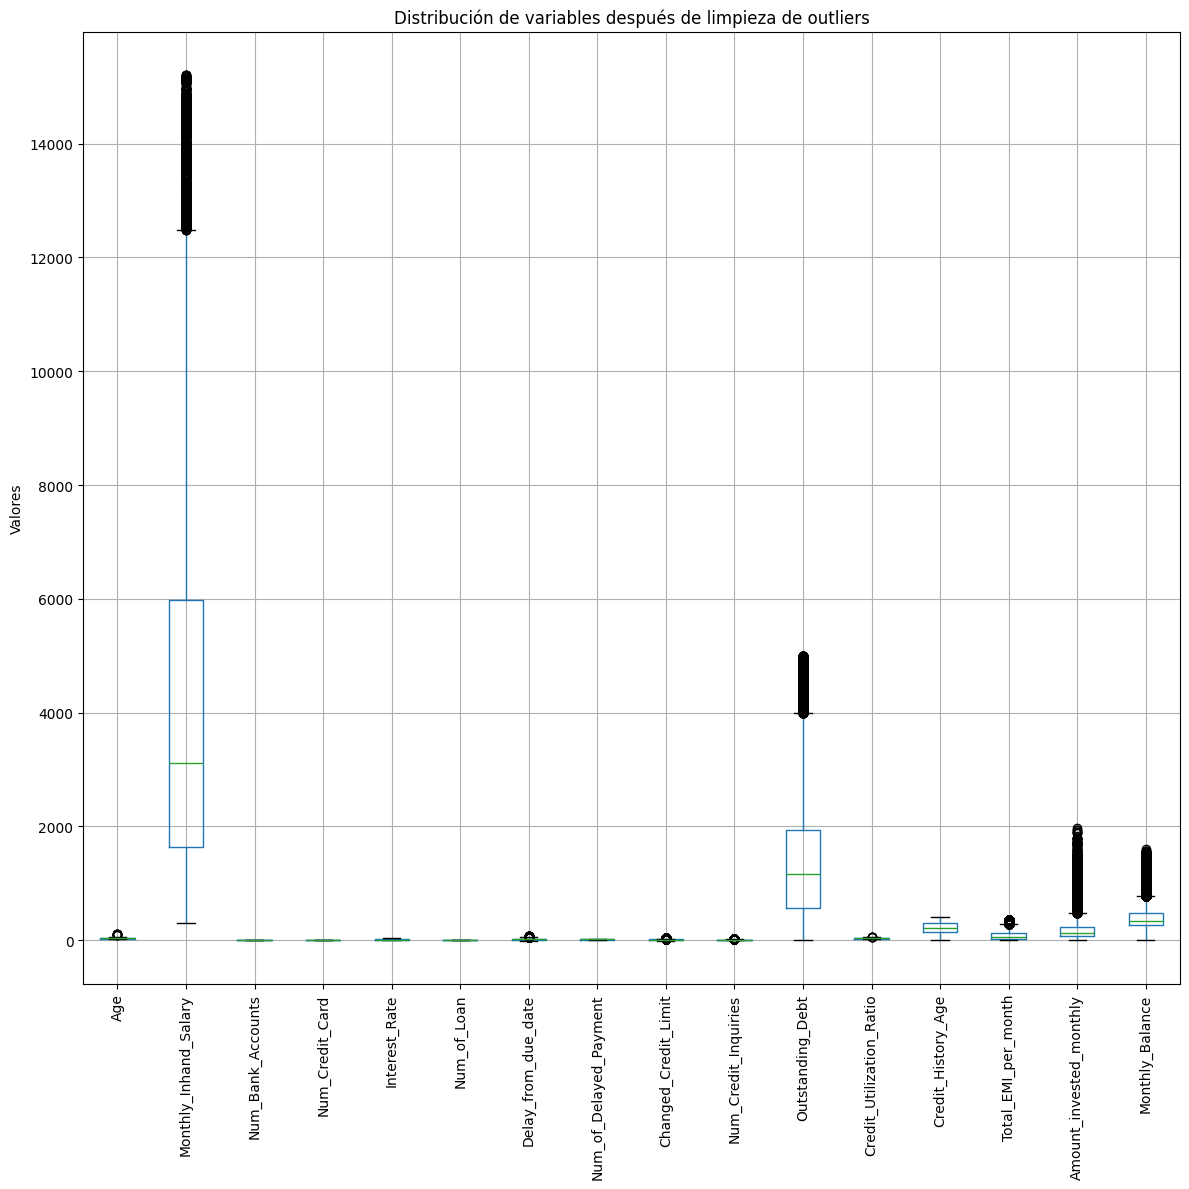

In [57]:
# Tratamiento de valores atípicos (todas las variables numéricas excepto Annual_Income)
# - Los valores fuera de límites se reemplazan por NaN para imputarlos después
# - No se eliminan filas: X_train debe seguir alineado con y_train y X_test debe conservar todos sus registros
df_x_train_out = df_x_train_cl.copy()

# Límites base: IQR calculado en train
limites_outliers = {col: (lim['lower'], lim['upper']) for col, lim in iqr_limits.items() if col != 'Annual_Income'}

# Edad: se mantiene el límite inferior IQR, pero el tope se eleva a 120 para no perder edades reales
limites_outliers['Age'] = (iqr_limits['Age']['lower'], 120)

# Variables de conteo: no pueden ser negativas (el IQR inferior no detecta valores como -1 o -3)
for col in ['Num_Bank_Accounts', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']:
    limites_outliers[col] = (0, iqr_limits[col]['upper'])

# Variables con colas largas pero reales: no se cortan por arriba, solo se eliminan negativos
for col in ['Monthly_Inhand_Salary', 'Monthly_Balance', 'Amount_invested_monthly', 'Outstanding_Debt', 'Credit_History_Age']:
    limites_outliers[col] = (0, np.inf)

# Variables con rango acotado y valores negativos válidos: no se modifican
for col in ['Delay_from_due_date', 'Changed_Credit_Limit', 'Credit_Utilization_Ratio']:
    limites_outliers.pop(col)

print("Valores atípicos reemplazados por NaN:")
for col, (lower, upper) in limites_outliers.items():
    mask = (df_x_train_out[col] < lower) | (df_x_train_out[col] > upper)
    df_x_train_out.loc[mask, col] = np.nan
    print(f"{col} [{lower}, {upper}]: {mask.sum()} ({mask.mean():.2%})")

# Boxplots posterior a limpieza de valores atípicos (sin Annual Income)
plt.figure(figsize=(12, 12))
df_x_train_out.drop(columns=['Annual_Income']).boxplot(rot=90)
plt.title('Distribución de variables después de limpieza de outliers')
plt.ylabel('Valores')
plt.tight_layout()
plt.show()


**Imputación de datos agrupando por cliente**

In [58]:
# Type_of_Loan: NaN significa que el cliente no tiene préstamos -> categoría propia antes de imputar
# Verificación: los NaN de Type_of_Loan deberían coincidir con Num_of_Loan == 0
print(pd.crosstab(df_x_train_out['Type_of_Loan'].isna(), df_x_train_out['Num_of_Loan'] == 0,
                  rownames=['Type_of_Loan NaN'], colnames=['Num_of_Loan == 0']))

df_x_train_out['Type_of_Loan'] = df_x_train_out['Type_of_Loan'].fillna('No Loan')

Num_of_Loan == 0  False  True 
Type_of_Loan NaN              
False             61973      0
True                310   7717


In [59]:
# Verificación de los casos con Type_of_Loan NaN y Num_of_Loan distinto de 0
casos = df_x_train_out['Type_of_Loan'].eq('No Loan') & df_x_train_out['Num_of_Loan'].ne(0)
print(df_x_train_out.loc[casos, 'Num_of_Loan'].value_counts(dropna=False))

# Clientes sin préstamos: Num_of_Loan = 0
df_x_train_out.loc[df_x_train_out['Type_of_Loan'].eq('No Loan'), 'Num_of_Loan'] = 0

Num_of_Loan
NaN    310
Name: count, dtype: int64


In [64]:
# Imputación de NaN por cliente usando el mes previo/siguiente con dato
# - Annual_Income: se asigna la moda del cliente a todas sus filas (el menor en caso de empate)
# - Resto de columnas: ffill/bfill dentro de cada cliente ordenado por mes
# - Respaldo: Monthly_Inhand_Salary = Annual_Income / 12; demás numéricas con mediana global y categóricas con moda global
meses = {'January': 1, 'February': 2, 'March': 3, 'April': 4,
         'May': 5, 'June': 6, 'July': 7, 'August': 8}

def imputar_por_cliente(df):
    df = df.copy()
    orden_original = df.index
    df['Month_num'] = df['Month'].map(meses)
    df = df.sort_values(['Customer_ID', 'Month_num'])

    # Annual_Income: moda del cliente para todas sus filas
    ingreso_original = df['Annual_Income'].copy()
    df['Annual_Income'] = df.groupby('Customer_ID')['Annual_Income'].transform(lambda s: s.mode().min())
    cambiados = ingreso_original != df['Annual_Income']
    print(f"Annual_Income corregidos: {cambiados.sum()} ({cambiados.mean():.2%})")

    # Resto de columnas con NaN: mes previo con dato y, si no existe, mes siguiente
    cols_na = [col for col in df.columns if df[col].isna().any()]
    df[cols_na] = df.groupby('Customer_ID')[cols_na].ffill()
    df[cols_na] = df.groupby('Customer_ID')[cols_na].bfill()

    # Respaldo de ingreso mensual: ingreso anual / 12
    if 'Monthly_Inhand_Salary' in cols_na:
        df['Monthly_Inhand_Salary'] = df['Monthly_Inhand_Salary'].fillna(df['Annual_Income'] / 12)

    # Respaldo para clientes sin ningún dato en la columna
    for col in cols_na:
        if df[col].isna().any():
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mode()[0])

    # Se recupera el orden original para mantener la alineación con y_train
    return df.loc[orden_original].drop(columns='Month_num')

df_x_train_imp = imputar_por_cliente(df_x_train_out)

# Características del conjunto de datos posterior a la imputación de NaN por cliente (sin Annual Income)
print(f"NaN restantes: {df_x_train_imp.isna().sum().sum()}")
df_x_train_imp.describe(include='all').T

Annual_Income corregidos: 700 (1.00%)
NaN restantes: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,70000,70000,0x1d653,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,70000,12498,CUS_0x59a5,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,70000,8,May,8814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,70000,10132,Stevex,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,70000.0,NaN,NaN,NaN,33.340486,10.791449,14.0,24.0,33.0,42.0,118.0
SSN,70000,12499,#F%$D@*&8,3909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,70000,15,Lawyer,5001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,70000.0,NaN,NaN,NaN,50561.023928,38197.2179,7005.93,19433.48,37225.38,71732.72,179987.28
Monthly_Inhand_Salary,70000.0,NaN,NaN,NaN,4203.156846,3178.811864,303.645417,1633.434167,3107.431667,5968.505,15204.633333
Num_Bank_Accounts,70000.0,NaN,NaN,NaN,5.361329,2.592893,0.0,3.0,5.0,7.0,11.0


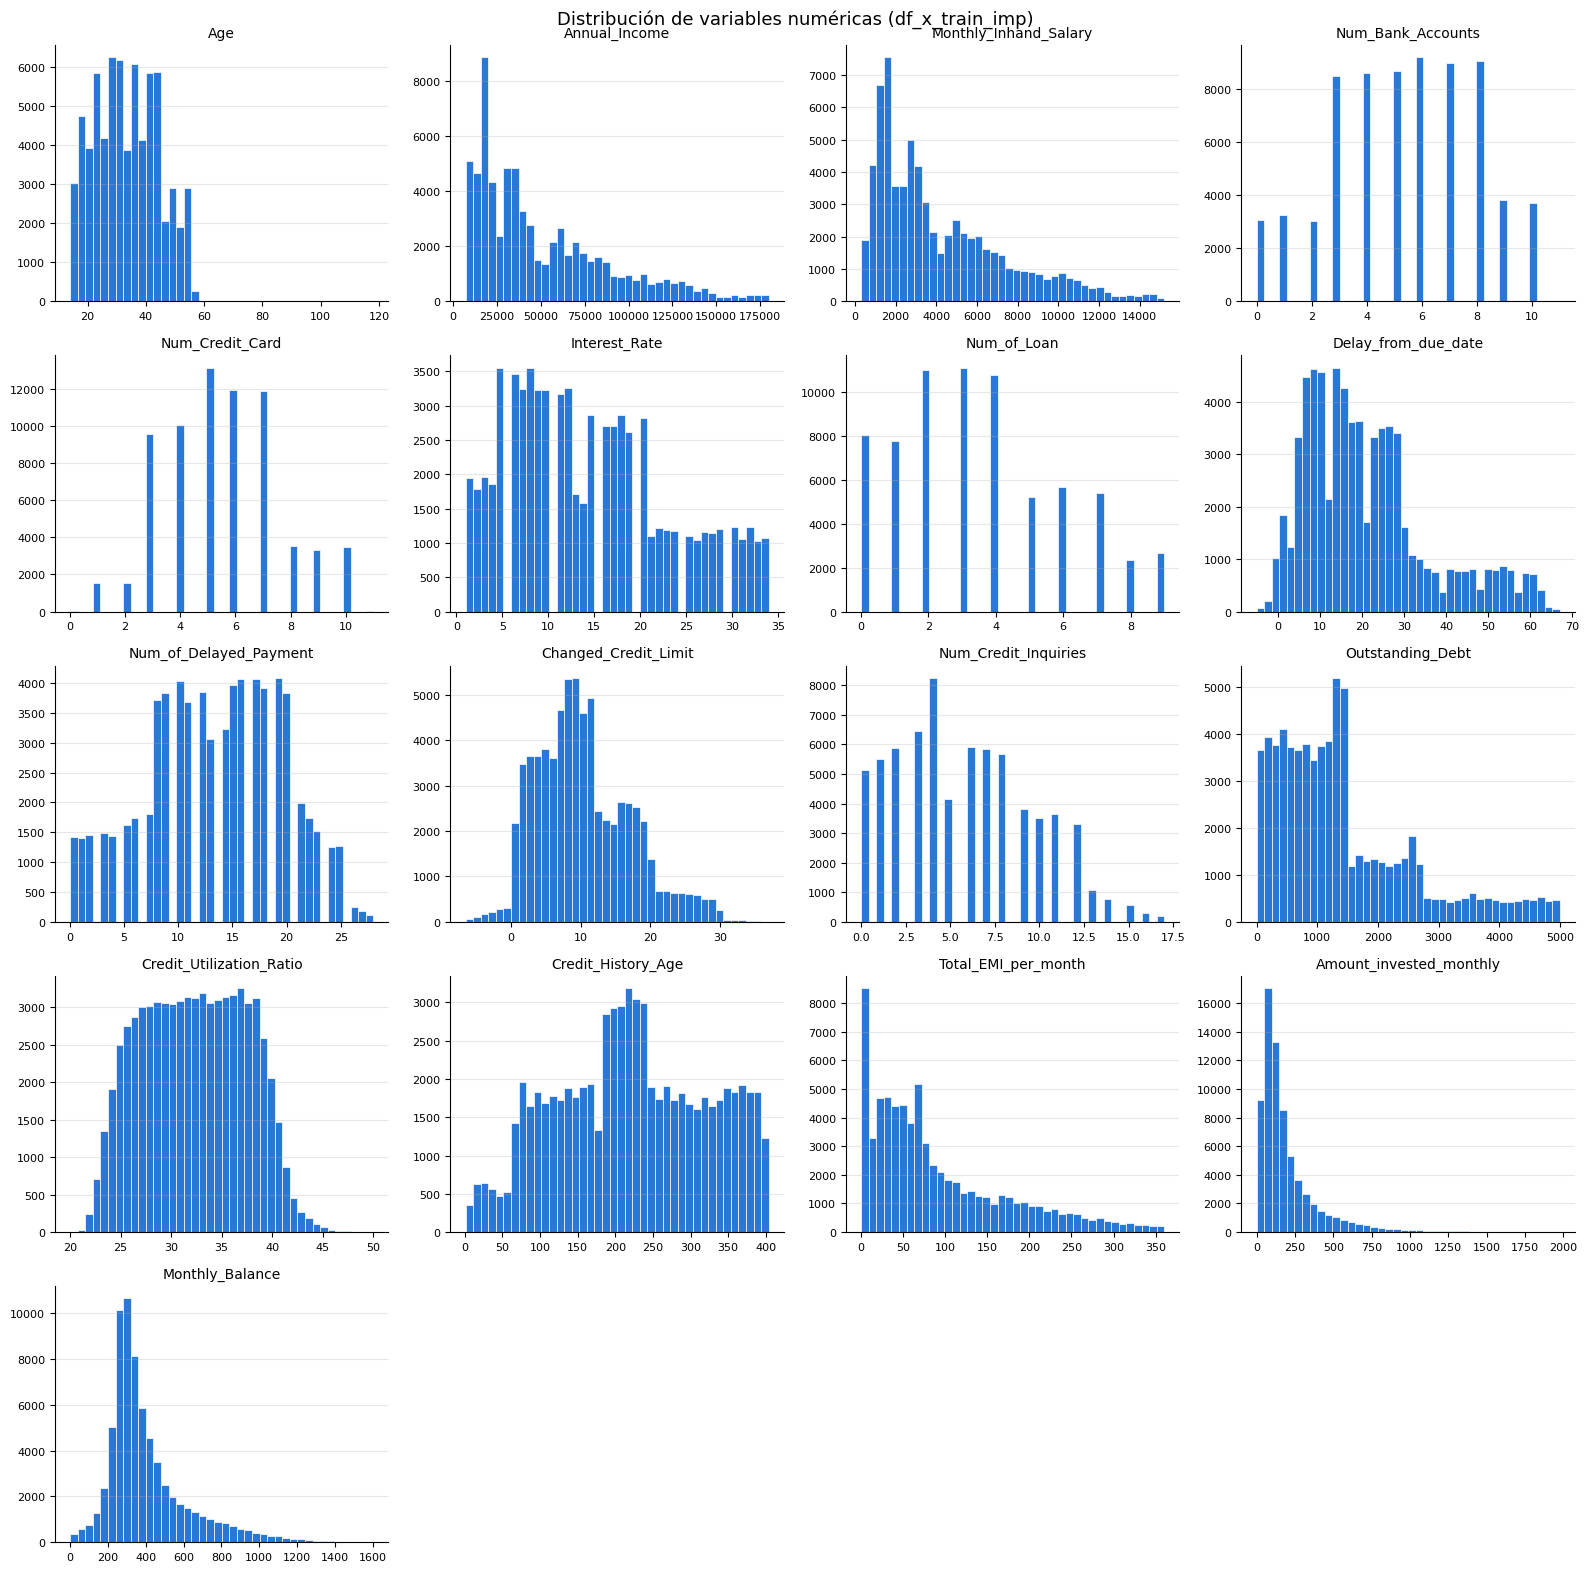

In [76]:
# Distribución de variables numéricas posterior a la imputación
cols_num = df_x_train_imp.select_dtypes(include='number').columns.tolist()
n_cols = 4
n_filas = int(np.ceil(len(cols_num) / n_cols))

fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas))
for ax, col in zip(axes.flat, cols_num):
    ax.hist(df_x_train_imp[col], bins=40, color='#2a78d6', edgecolor='white', linewidth=0.5)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(cols_num):]:
    ax.set_visible(False)

fig.suptitle('Distribución de variables numéricas (df_x_train_imp)', fontsize=13)
plt.tight_layout()
plt.show()


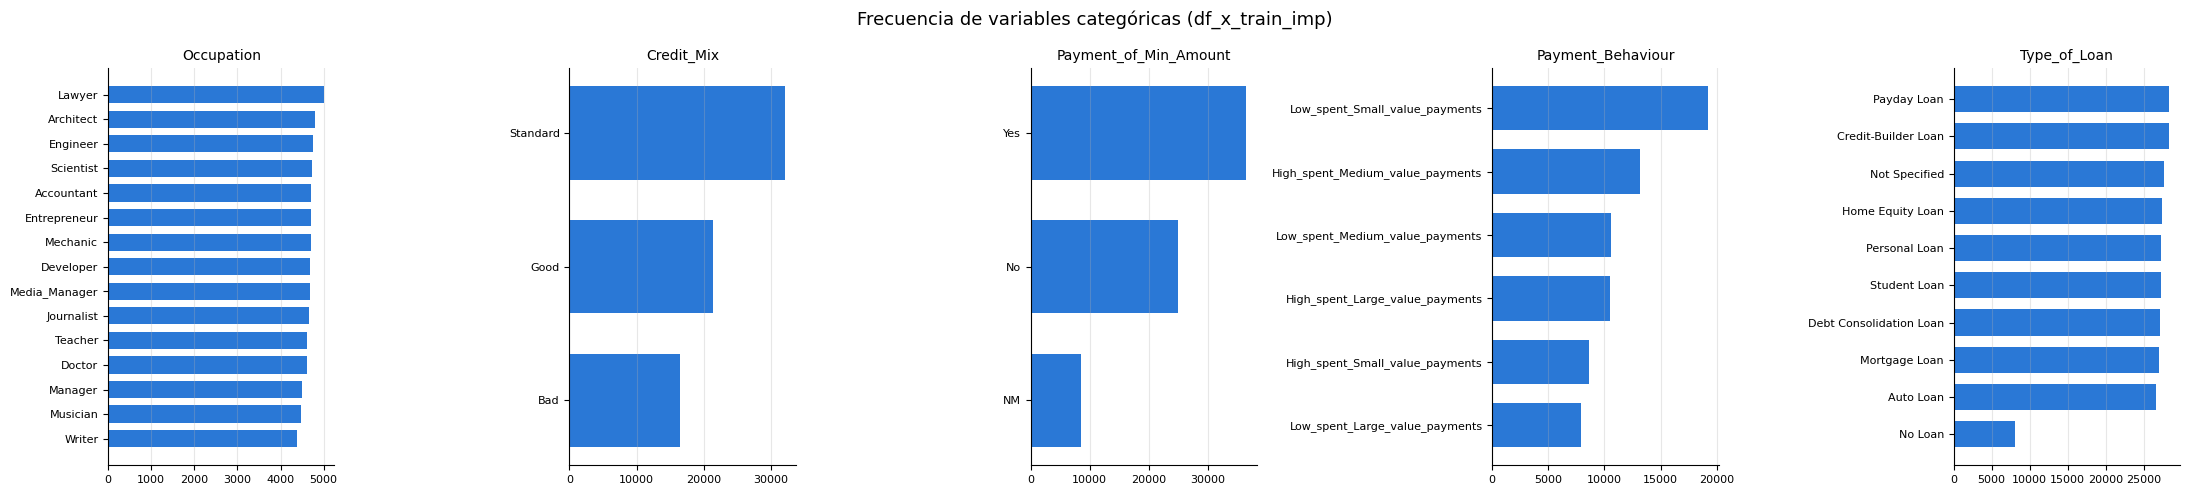

In [77]:
# Distribución de variables categóricas posterior a la imputación
# Type_of_Loan se separa por tipo de préstamo (un cliente puede tener varios)
categoricas = {
    'Occupation': df_x_train_imp['Occupation'],
    'Credit_Mix': df_x_train_imp['Credit_Mix'],
    'Payment_of_Min_Amount': df_x_train_imp['Payment_of_Min_Amount'],
    'Payment_Behaviour': df_x_train_imp['Payment_Behaviour'],
    'Type_of_Loan': df_x_train_imp['Type_of_Loan'].str.replace('and ', '', regex=False).str.split(', ').explode(),
}

fig, axes = plt.subplots(1, len(categoricas), figsize=(22, 5))
for ax, (nombre, serie) in zip(axes, categoricas.items()):
    conteo = serie.value_counts().sort_values()
    ax.barh(conteo.index, conteo.values, color='#2a78d6', height=0.7)
    ax.set_title(nombre, fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Frecuencia de variables categóricas (df_x_train_imp)', fontsize=13)
plt.tight_layout()
plt.show()


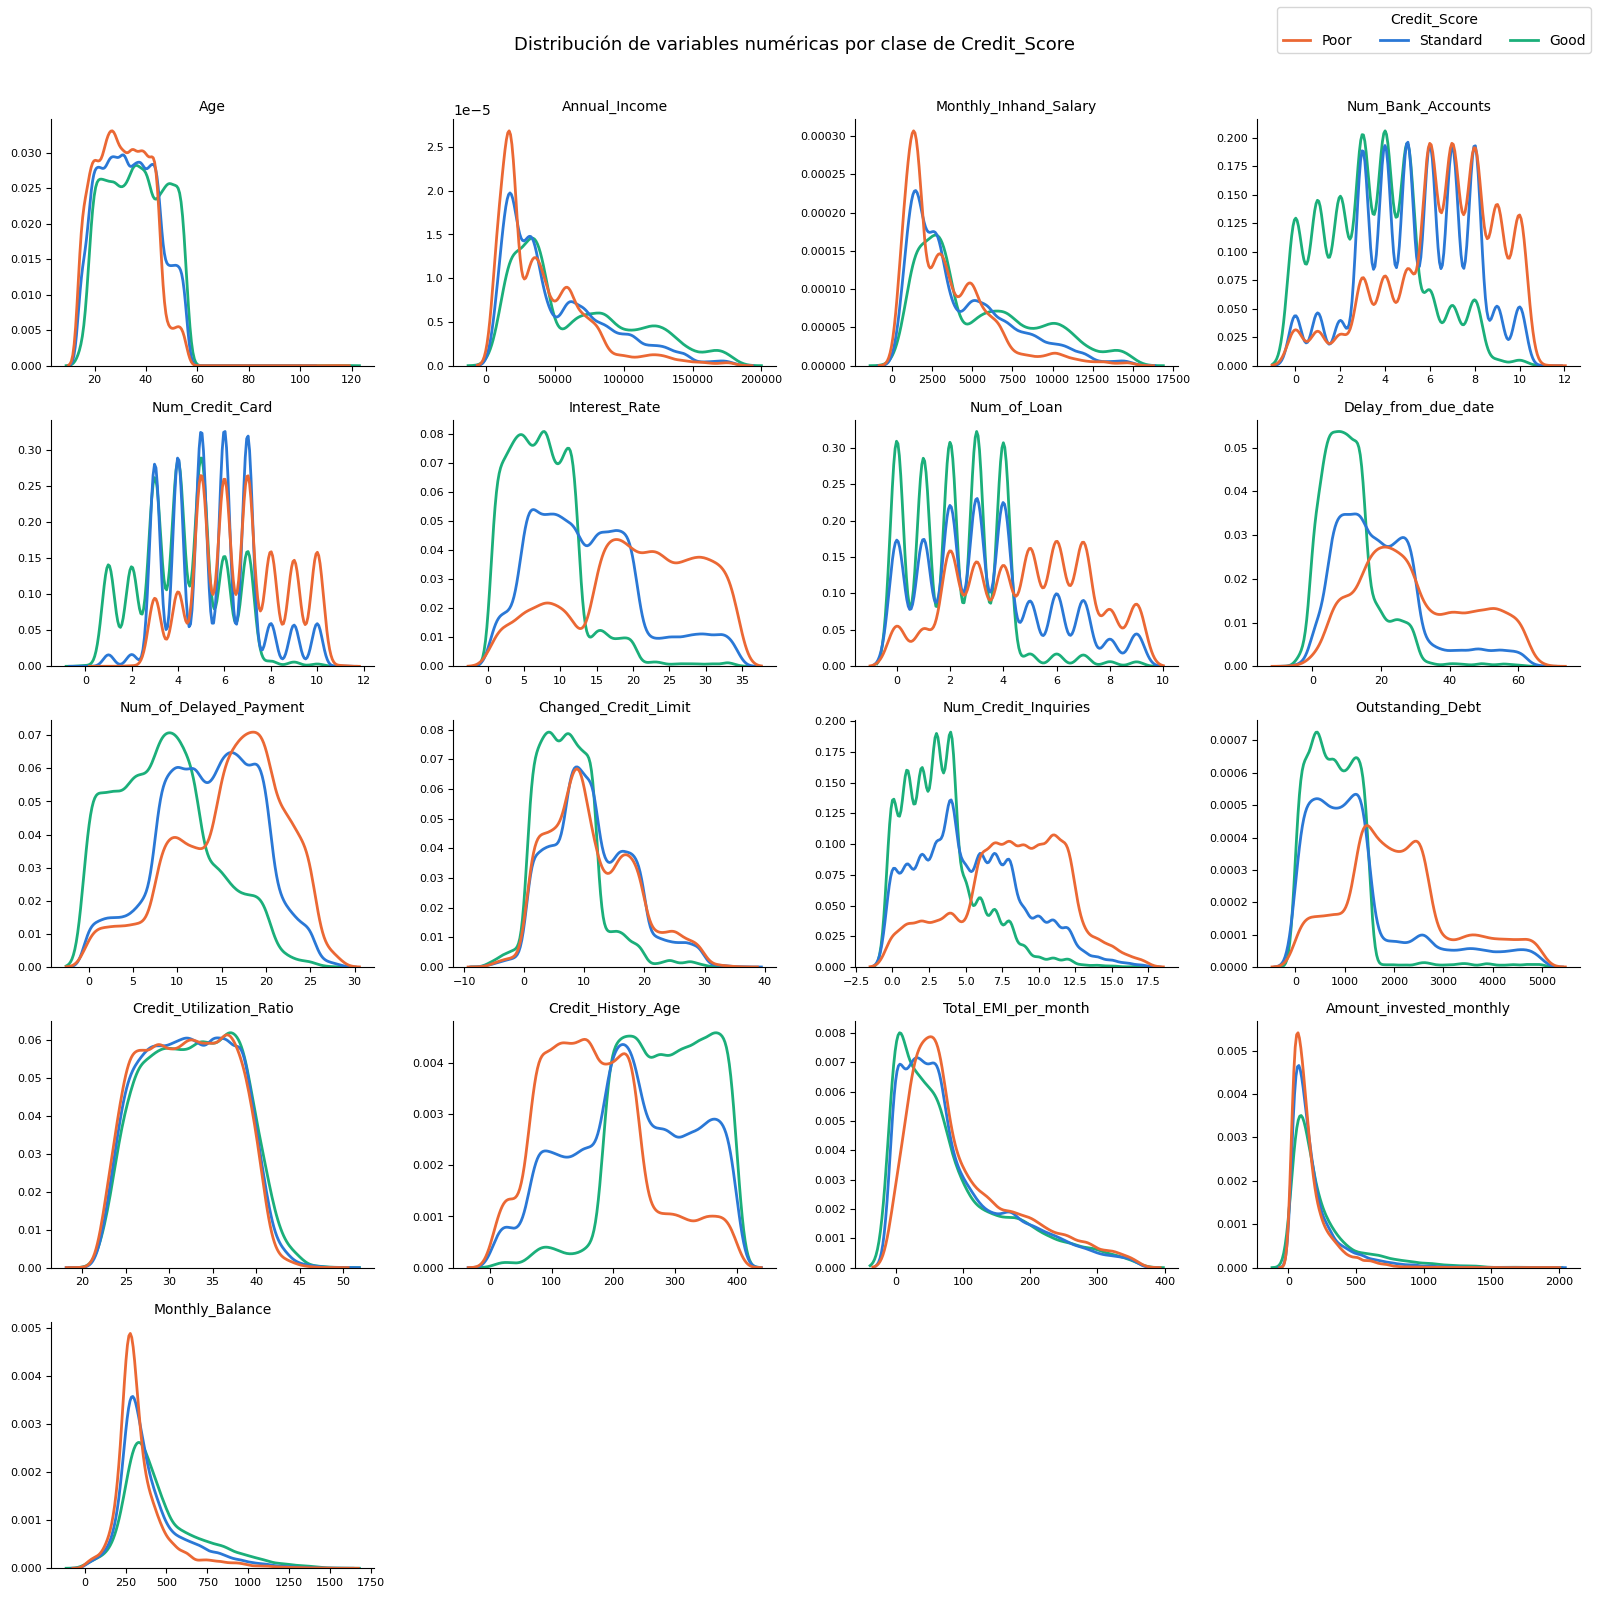

In [78]:
# Distribución de variables numéricas por clase de Credit_Score
# - Curvas casi superpuestas: la variable aporta poca información para separar las clases
# - Curvas desplazadas entre sí: la variable ayuda a discriminar
df_eda = df_x_train_imp[cols_num].assign(Credit_Score=df_y_train['Credit_Score'].values)
colores_clase = {'Poor': '#eb6834', 'Standard': '#2a78d6', 'Good': '#1baf7a'}

fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas))
for ax, col in zip(axes.flat, cols_num):
    sns.kdeplot(data=df_eda, x=col, hue='Credit_Score', palette=colores_clase,
                common_norm=False, linewidth=2, ax=ax, legend=False)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(cols_num):]:
    ax.set_visible(False)

handles = [plt.Line2D([0], [0], color=c, linewidth=2) for c in colores_clase.values()]
fig.legend(handles, colores_clase.keys(), title='Credit_Score', loc='upper right', ncol=3)
fig.suptitle('Distribución de variables numéricas por clase de Credit_Score', fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [65]:
# Codificación de variables categóricas
# - Type_of_Loan: una columna binaria por tipo de préstamo (multi-hot), incluye 'No Loan' y 'Not Specified'
# - Credit_Mix: ordinal (Bad=0, Standard=1, Good=2)
# - Occupation, Payment_of_Min_Amount, Payment_Behaviour: one-hot
# - Se eliminan identificadores y variables sin valor predictivo
def codificar(df):
    df = df.copy()

    prestamos = (df['Type_of_Loan']
                 .str.replace('and ', '', regex=False)
                 .str.get_dummies(sep=', ')
                 .add_prefix('Loan_'))

    df['Credit_Mix'] = df['Credit_Mix'].map({'Bad': 0, 'Standard': 1, 'Good': 2})

    df = pd.get_dummies(df, columns=['Occupation', 'Payment_of_Min_Amount', 'Payment_Behaviour'], dtype=int)
    df = pd.concat([df.drop(columns=['Type_of_Loan']), prestamos], axis=1)

    return df.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN', 'Month'])

X_train = codificar(df_x_train_imp)

print(f"Dimensiones: {X_train.shape}")
print(f"Columnas no numéricas: {X_train.select_dtypes(exclude='number').columns.tolist()}")
print(f"NaN restantes: {X_train.isna().sum().sum()}")
X_train.filter(like='Loan_').sum().sort_values(ascending=False)


Dimensiones: (70000, 52)
Columnas no numéricas: []
NaN restantes: 0


Loan_Payday Loan                22311
Loan_Credit-Builder Loan        22267
Loan_Not Specified              22118
Loan_Home Equity Loan           22034
Loan_Personal Loan              21808
Loan_Mortgage Loan              21737
Loan_Student Loan               21728
Loan_Debt Consolidation Loan    21654
Loan_Auto Loan                  21340
Loan_No Loan                     8027
dtype: int64

In [83]:
# Relevancia de variables respecto a Credit_Score
# Tabla 1 (numéricas): mediana por clase + eta² (proporción de la varianza explicada por la clase)
#   eta² < 0.01 despreciable | 0.01–0.06 pequeño | 0.06–0.14 mediano | > 0.14 grande
# Tabla 2 (todas las columnas de X_train): información mutua con Credit_Score (0 = no aporta)
from sklearn.feature_selection import mutual_info_classif

y_eda = df_y_train['Credit_Score'].values
orden_clases = ['Poor', 'Standard', 'Good']

def eta_cuadrado(x, y):
    grupos = pd.Series(x).groupby(y)
    media = x.mean()
    ss_entre = sum(len(g) * (g.mean() - media) ** 2 for _, g in grupos)
    ss_total = ((x - media) ** 2).sum()
    return ss_entre / ss_total

tabla_num = df_x_train_imp[cols_num].groupby(y_eda).median().T[orden_clases]
tabla_num.columns = [f'Mediana {c}' for c in orden_clases]
tabla_num['eta²'] = [eta_cuadrado(df_x_train_imp[col].values, y_eda) for col in cols_num]
tabla_num = tabla_num.sort_values('eta²', ascending=False)

display(tabla_num.style.format('{:.2f}').format('{:.3f}', subset=['eta²'])
        .background_gradient(subset=['eta²'], cmap='Blues'))

# Información mutua sobre X_train codificado (incluye dummies de Occupation y Type_of_Loan)
discretas = (X_train.nunique() <= 2).values
mi = pd.Series(mutual_info_classif(X_train, y_eda, discrete_features=discretas, random_state=42),
               index=X_train.columns, name='Información mutua').sort_values(ascending=False)

display(mi.to_frame().style.format('{:.4f}').background_gradient(cmap='Blues'))


,Mediana Poor,Mediana Standard,Mediana Good,eta²
Interest_Rate,21.00,13.00,7.00,0.236
Num_Credit_Inquiries,8.00,5.00,3.00,0.192
Delay_from_due_date,27.00,18.00,10.00,0.187
Num_Credit_Card,7.00,5.00,4.00,0.164
Num_Bank_Accounts,7.00,5.00,3.00,0.156
Outstanding_Debt,1941.98,996.99,746.05,0.153
Credit_History_Age,161.00,227.00,288.00,0.149
Num_of_Delayed_Payment,17.00,14.00,8.00,0.149
Num_of_Loan,5.00,3.00,2.00,0.130
Changed_Credit_Limit,9.73,10.31,6.72,0.051


,Información mutua
Annual_Income,0.5798
Outstanding_Debt,0.5785
Monthly_Inhand_Salary,0.5729
Total_EMI_per_month,0.5072
Credit_Mix,0.1913
Interest_Rate,0.1693
Delay_from_due_date,0.1261
Num_Credit_Inquiries,0.1189
Num_Credit_Card,0.1095
Credit_History_Age,0.1045


In [ ]:
# Proporción de Credit_Score por categoría vs. proporción general para las variables categóricas generadas
# - Si las filas se parecen a la fila 'General', la variable aporta poco
df_eda_cat = df_x_train_imp[['Occupation', 'Type_of_Loan']].assign(Credit_Score=df_y_train['Credit_Score'].values)
orden_clases = ['Poor', 'Standard', 'Good']
general = df_eda_cat['Credit_Score'].value_counts(normalize=True)[orden_clases].rename('General')

# Occupation
tabla_occ = pd.crosstab(df_eda_cat['Occupation'], df_eda_cat['Credit_Score'], normalize='index')[orden_clases]
display(pd.concat([tabla_occ, general.to_frame().T]).style.format('{:.1%}').background_gradient(axis=0, cmap='Blues'))

# Type_of_Loan (separado por tipo de préstamo)
prestamos_eda = df_eda_cat.assign(
    Type_of_Loan=df_eda_cat['Type_of_Loan'].str.replace('and ', '', regex=False).str.split(', ')
).explode('Type_of_Loan')
tabla_loan = pd.crosstab(prestamos_eda['Type_of_Loan'], prestamos_eda['Credit_Score'], normalize='index')[orden_clases]
display(pd.concat([tabla_loan, general.to_frame().T]).style.format('{:.1%}').background_gradient(axis=0, cmap='Blues'))


Credit_Score,Poor,Standard,Good
Accountant,30.4%,51.5%,18.0%
Architect,27.0%,54.8%,18.3%
Developer,28.4%,53.3%,18.3%
Doctor,27.5%,55.2%,17.3%
Engineer,29.8%,52.0%,18.2%
Entrepreneur,31.0%,51.4%,17.6%
Journalist,27.8%,53.4%,18.9%
Lawyer,27.7%,54.2%,18.2%
Manager,28.7%,52.7%,18.7%
Mechanic,30.5%,53.2%,16.3%


Credit_Score,Poor,Standard,Good
Auto Loan,39.2%,50.0%,10.8%
Credit-Builder Loan,38.5%,50.2%,11.3%
Debt Consolidation Loan,39.4%,49.9%,10.6%
Home Equity Loan,38.7%,50.3%,11.0%
Mortgage Loan,38.9%,49.8%,11.3%
No Loan,11.5%,58.2%,30.2%
Not Specified,38.5%,49.8%,11.7%
Payday Loan,39.2%,49.8%,11.0%
Personal Loan,38.6%,50.7%,10.7%
Student Loan,39.2%,49.3%,11.5%


**Limpieza de X_test**

In [ ]:
# Aplicación de la misma limpieza a X_test
# 1) Conversión de texto a número y de Credit_History_Age a meses
# 2) Marcadores basura -> NaN
# 3) Outliers -> NaN usando los límites calculados en train (limites_outliers)
# 4) Type_of_Loan NaN -> 'No Loan' y Num_of_Loan = 0
# 5) Imputación por cliente junto con train (los clientes del test también aparecen en train)
# 6) Codificación y alineación de columnas con X_train
df_x_test_out = df_x_test.copy()

# 1) Conversión a numérico
for col in cols_guion:
    df_x_test_out[col] = pd.to_numeric(
        df_x_test_out[col].astype(str).str.replace('_', '', regex=False),
        errors='coerce'
    )

anios_meses = df_x_test_out['Credit_History_Age'].str.extract(r'(\d+)\s*Years?\D*(\d+)\s*Months?')
df_x_test_out['Credit_History_Age'] = anios_meses[0].astype(float) * 12 + anios_meses[1].astype(float)

# 2) Marcadores basura
df_x_test_out['Occupation'] = df_x_test_out['Occupation'].replace('_______', np.nan)
df_x_test_out['Credit_Mix'] = df_x_test_out['Credit_Mix'].replace('_', np.nan)
df_x_test_out['Payment_Behaviour'] = df_x_test_out['Payment_Behaviour'].replace('!@9#%8', np.nan)
df_x_test_out['Amount_invested_monthly'] = df_x_test_out['Amount_invested_monthly'].replace(10000, np.nan)
df_x_test_out['Monthly_Balance'] = df_x_test_out['Monthly_Balance'].replace(-333333333333333333333333333, np.nan)

# 3) Valores atípicos con los límites de train
for col, (lower, upper) in limites_outliers.items():
    mask = (df_x_test_out[col] < lower) | (df_x_test_out[col] > upper)
    df_x_test_out.loc[mask, col] = np.nan

# 4) Clientes sin préstamos
df_x_test_out['Type_of_Loan'] = df_x_test_out['Type_of_Loan'].fillna('No Loan')
df_x_test_out.loc[df_x_test_out['Type_of_Loan'].eq('No Loan'), 'Num_of_Loan'] = 0

# 5) Imputación conjunta con train y separación del test
conjunto_imp = imputar_por_cliente(pd.concat([df_x_train_out, df_x_test_out], ignore_index=True))
df_x_test_imp = conjunto_imp.iloc[len(df_x_train_out):].reset_index(drop=True)

# 6) Codificación con las mismas columnas que X_train
X_test = codificar(df_x_test_imp).reindex(columns=X_train.columns, fill_value=0)

print(f"Dimensiones: {X_test.shape}")
print(f"NaN restantes: {X_test.isna().sum().sum()}")
print(f"Columnas iguales a X_train: {list(X_test.columns) == list(X_train.columns)}")

Annual_Income corregidos: 999 (1.00%)
Dimensiones: (30000, 52)
NaN restantes: 0
Columnas iguales a X_train: True


In [ ]:
y_train = df_y_train['Credit_Score']

Se ejecutó una corrida con todas las variables, obteniendo un puntaje de 0.673726009265 en la carga original. Posterior al análisis de la relevancia con respecto a Credit_score, se eliminan variables que no aportan al modelo. (La segunda ejecución mejoró el modelo, obteniendo 0.708802117802)

In [84]:
# Eliminación de variables con aporte nulo o muy bajo según eta² e información mutua
# - Occupation_*, Payment_Behaviour_*, Loan_*: información mutua ≈ 0
# - Credit_Utilization_Ratio (eta² = 0.002) y Total_EMI_per_month (eta² = 0.006)
cols_eliminar = ([c for c in X_train.columns if c.startswith(('Occupation_', 'Payment_Behaviour_', 'Loan_'))]
                 + ['Credit_Utilization_Ratio', 'Total_EMI_per_month'])

X_train = X_train.drop(columns=cols_eliminar)
X_test = X_test.drop(columns=cols_eliminar)

print(f"Columnas eliminadas: {len(cols_eliminar)}")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Columnas iguales: {list(X_train.columns) == list(X_test.columns)}")
print(X_train.columns.tolist())


Columnas eliminadas: 33
X_train: (70000, 19) | X_test: (30000, 19)
Columnas iguales: True
['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_History_Age', 'Amount_invested_monthly', 'Monthly_Balance', 'Payment_of_Min_Amount_NM', 'Payment_of_Min_Amount_No', 'Payment_of_Min_Amount_Yes']


### **5. Classifier (do not modify)**

In [85]:
# Definimos el modelo RandomForestClassifier 
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

c:\Users\darth\.conda\envs\env_mcd\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

### **6. Predictions for Kaggle**

In [86]:
# Aplicar misma limpieza a X_test antes de predecir

y_pred = model.predict(X_test)

### **7. Generate submission file**

In [87]:
# Importamos la base de datos 'sample_submission.csv' descargada de Kaggle
import pandas as pd

submission = pd.read_csv('iisem-2026-mcd-credit-score/sample_submission_credit.csv')

# Reemplazamos la columna 'class' en el archivo de submission con las predicciones y_pred
submission['class'] = y_pred

# Guardamos el archivo submission en formato CSV
submission.to_csv('submission.csv', index=False)

### **8. Rúbrica de Evaluación**

**Evaluación basada en posición en el leaderboard de Kaggle** 

**Pregrado:**

| Posición en el leaderboard | Calificación /10 | Calificación /6 |
|----------------------------|------------------|-----------------|
| 1.er lugar                 | 10               | 6               |
| 2.º lugar                 | 9.6              | 5.76             |
| 3.er lugar                | 9.2              | 5.52             |
| 4.º lugar                 | 8.8              | 5.28             |
| 5.º lugar                 | 8.4              | 5.04             |
| 6.º lugar                 | 8.0              | 4.8              |
| 7.º lugar                 | 7.8              | 4.68             |
| 8.º lugar                 | 7.6              | 4.56             |
| 9.º lugar                 | 7.4              | 4.44             |
| 10.º lugar                | 7.2              | 4.32             |
| 11.º lugar                | 7.0              | 4.25             |
| No entregó                | 0                | 0                |

**Postgrado**

| Posición en el leaderboard | Calificación /10 | 
|----------------------------|------------------|
| 1.er lugar                 | 10               |
| 2.º lugar                 | 9.5             | 
| 3.er lugar                | 9              |
| 4.º lugar                 | 8.5              | 
| 5.º lugar                 | 8              | 